# Step 0.5 — Extraction Benchmark: mmore vs Docling

Compare extraction quality on the same 474-page medical PDF.

**Inputs:**
- `out/mmore/mmore_output.json` — mmore raw output
- `output.json` — Docling raw output
- `data/source.pdf` — original PDF

**What we measure:**
1. Text coverage per page
2. Table detection & accuracy
3. Word-level agreement (Jaccard)
4. Problem pages
5. Detailed side-by-side on key pages

In [7]:
import json, re
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np

# --- PATHS: change these to match your setup ---
MMORE_PATH = "out/mmore/mmore_output.json"
DOCLING_PATH = "ocr/output.json"
PDF_PATH = "data/source.pdf"
KEY_PAGES = [43, 57, 104, 115, 229, 253, 338]


In [9]:
# Helper functions

def get_words(text):
    return re.findall(r'[a-z]{3,}', text.lower())

def jaccard(a, b):
    wa, wb = set(get_words(a)), set(get_words(b))
    if not wa and not wb: return 1.0
    if not wa or not wb: return 0.0
    return len(wa & wb) / len(wa | wb)

def word_count(text):
    return len(text.split())

def has_khmer(text):
    return any(0x1780 <= ord(c) <= 0x17FF for c in text)

def has_table_markers(text):
    return text.count('|') > 10 and any('---' in line for line in text.split('\n'))


In [10]:
!pwd

/mnt/upschrimpf2/scratch/mahdipou/ml


## 1. Load mmore output

In [11]:
with open(MMORE_PATH) as f:
    mmore_raw = json.load(f)

mmore_text = mmore_raw.get('text', '')
mmore_paras = mmore_raw.get('metadata', {}).get('paragraph_starts', [])
mmore_images = mmore_raw.get('modalities', [])

# Split text by page using paragraph_starts
mmore_pages = defaultdict(str)
for i, entry in enumerate(mmore_paras):
    if isinstance(entry, (list, tuple)) and len(entry) >= 2:
        offset, page = entry[0], entry[1]
        if page == -1:
            continue
        next_offset = (mmore_paras[i+1][0]
                      if i+1 < len(mmore_paras) and isinstance(mmore_paras[i+1], (list, tuple))
                      and mmore_paras[i+1][0] > offset
                      else len(mmore_text))
        mmore_pages[page] += mmore_text[offset:next_offset] + '\n'

mmore_pages = dict(mmore_pages)
print(f"mmore: {len(mmore_pages)} pages, {len(mmore_images)} images")
print(f"Total words: {sum(word_count(v) for v in mmore_pages.values()):,}")


mmore: 474 pages, 179 images
Total words: 131,615


## 2. Load Docling output

In [13]:
with open(DOCLING_PATH) as f:
    docling_raw = json.load(f)

docling_texts = docling_raw.get('texts', [])
docling_tables = docling_raw.get('tables', [])
docling_pics = docling_raw.get('pictures', [])

# Split text by page
docling_pages = defaultdict(str)
for item in docling_texts:
    page = item['prov'][0]['page_no'] if item.get('prov') else None
    if page is not None:
        docling_pages[page] += item.get('text', '') + '\n'
docling_pages = dict(docling_pages)

# Map tables to pages
docling_table_pages = defaultdict(list)
for table in docling_tables:
    page = table['prov'][0]['page_no'] if table.get('prov') else None
    grid = table.get('data', {}).get('grid', [])
    rows, cols = len(grid), len(grid[0]) if grid else 0
    total = rows * cols
    empty = sum(1 for r in grid for c in r
                if not (c.get('text', '') if isinstance(c, dict) else str(c)).strip())
    fill = (total - empty) / total if total > 0 else 0
    if page is not None:
        docling_table_pages[page].append({
            'rows': rows, 'cols': cols,
            'fill_rate': round(fill, 2),
            'collapsed': rows <= 1
        })

print(f"Docling: {len(docling_pages)} pages, {len(docling_tables)} tables, {len(docling_pics)} pictures")
print(f"Total words: {sum(word_count(v) for v in docling_pages.values()):,}")


Docling: 474 pages, 156 tables, 184 pictures
Total words: 116,434


## 3. Summary comparison

In [14]:
summary = {
    'Metric': ['Pages with text', 'Total words', 'Images/Pictures',
               'Structured tables', 'Has Khmer text'],
    'mmore': [
        len(mmore_pages),
        f"{sum(word_count(v) for v in mmore_pages.values()):,}",
        len(mmore_images),
        '—',
        sum(1 for v in mmore_pages.values() if has_khmer(v)),
    ],
    'Docling': [
        len(docling_pages),
        f"{sum(word_count(v) for v in docling_pages.values()):,}",
        len(docling_pics),
        len(docling_tables),
        sum(1 for v in docling_pages.values() if has_khmer(v)),
    ]
}

# Print as a simple table
print(f"{'Metric':<25} {'mmore':>12} {'Docling':>12}")
print("-" * 50)
for i, m in enumerate(summary['Metric']):
    print(f"{m:<25} {str(summary['mmore'][i]):>12} {str(summary['Docling'][i]):>12}")


Metric                           mmore      Docling
--------------------------------------------------
Pages with text                    474          474
Total words                    131,615      116,434
Images/Pictures                    179          184
Structured tables                    —          156
Has Khmer text                       5            1


## 4. Per-page word count comparison

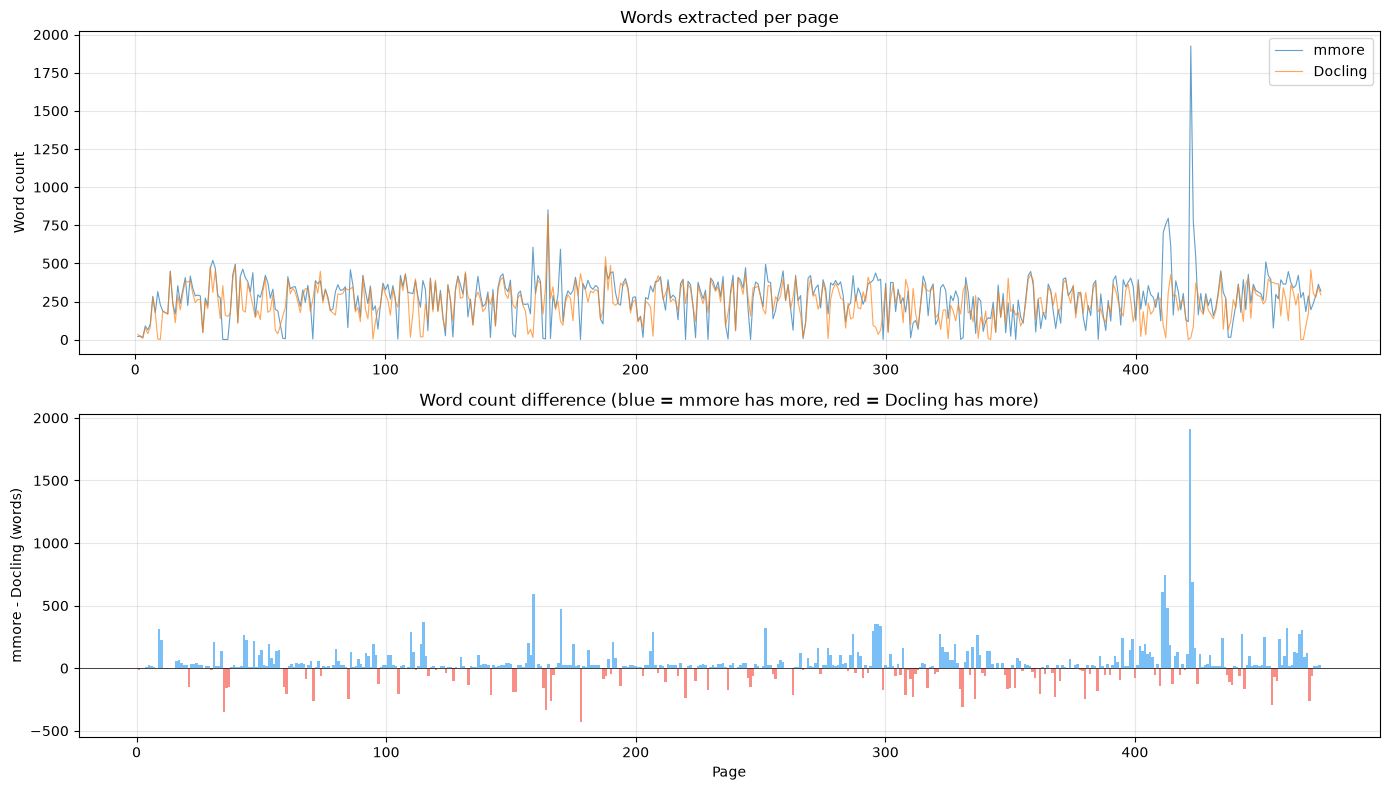

Saved: word_count_comparison.png


In [15]:
all_pages = sorted(set(list(mmore_pages.keys()) + list(docling_pages.keys())))

m_counts = [word_count(mmore_pages.get(p, '')) for p in all_pages]
d_counts = [word_count(docling_pages.get(p, '')) for p in all_pages]

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Top: word counts
axes[0].plot(all_pages, m_counts, alpha=0.7, label='mmore', linewidth=0.8)
axes[0].plot(all_pages, d_counts, alpha=0.7, label='Docling', linewidth=0.8)
axes[0].set_ylabel('Word count')
axes[0].set_title('Words extracted per page')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Bottom: difference
diff = [m - d for m, d in zip(m_counts, d_counts)]
colors = ['#2196F3' if d > 0 else '#F44336' for d in diff]
axes[1].bar(all_pages, diff, color=colors, alpha=0.6, width=1.0)
axes[1].axhline(y=0, color='black', linewidth=0.5)
axes[1].set_xlabel('Page')
axes[1].set_ylabel('mmore - Docling (words)')
axes[1].set_title('Word count difference (blue = mmore has more, red = Docling has more)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('word_count_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: word_count_comparison.png")


## 5. Page-level agreement (Jaccard similarity)

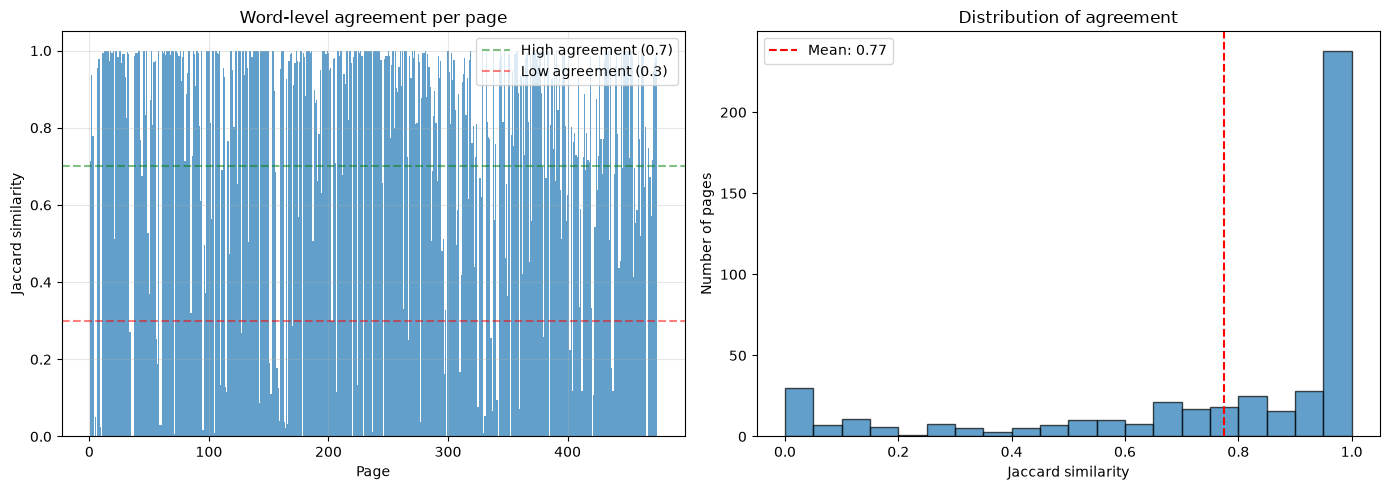

High agreement (>= 0.7): 342 pages (72%)
Medium (0.3 - 0.7):      69 pages (15%)
Low (< 0.3):             63 pages (13%)


In [16]:
similarities = []
for p in all_pages:
    m_text = mmore_pages.get(p, '')
    d_text = docling_pages.get(p, '')
    sim = jaccard(m_text, d_text)
    similarities.append({'page': p, 'jaccard': sim,
                         'mmore_words': word_count(m_text),
                         'docling_words': word_count(d_text)})

sims = [s['jaccard'] for s in similarities]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: similarity per page
axes[0].bar([s['page'] for s in similarities], sims, width=1.0, alpha=0.7)
axes[0].axhline(y=0.7, color='green', linestyle='--', alpha=0.5, label='High agreement (0.7)')
axes[0].axhline(y=0.3, color='red', linestyle='--', alpha=0.5, label='Low agreement (0.3)')
axes[0].set_xlabel('Page')
axes[0].set_ylabel('Jaccard similarity')
axes[0].set_title('Word-level agreement per page')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Right: histogram
axes[1].hist(sims, bins=20, edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Jaccard similarity')
axes[1].set_ylabel('Number of pages')
axes[1].set_title('Distribution of agreement')
axes[1].axvline(x=np.mean(sims), color='red', linestyle='--', label=f'Mean: {np.mean(sims):.2f}')
axes[1].legend()

plt.tight_layout()
plt.savefig('agreement_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

high = sum(1 for s in sims if s >= 0.7)
mid = sum(1 for s in sims if 0.3 <= s < 0.7)
low = sum(1 for s in sims if s < 0.3)
print(f"High agreement (>= 0.7): {high} pages ({high/len(sims)*100:.0f}%)")
print(f"Medium (0.3 - 0.7):      {mid} pages ({mid/len(sims)*100:.0f}%)")
print(f"Low (< 0.3):             {low} pages ({low/len(sims)*100:.0f}%)")


## 6. Problem pages (low agreement)

In [17]:
problems = [s for s in similarities if s['jaccard'] < 0.3
            and (s['mmore_words'] > 30 or s['docling_words'] > 30)]

print(f"Found {len(problems)} problem pages:\n")
print(f"{'Page':>6} {'Jaccard':>8} {'mmore':>8} {'Docling':>8} {'Reason'}")
print("-" * 55)
for s in sorted(problems, key=lambda x: x['jaccard']):
    reason = ""
    if s['mmore_words'] > 0 and s['docling_words'] == 0:
        reason = "Docling empty"
    elif s['docling_words'] > 0 and s['mmore_words'] == 0:
        reason = "mmore empty"
    elif has_khmer(mmore_pages.get(s['page'], '')):
        reason = "Khmer content"
    else:
        reason = "Content differs"
    print(f"{s['page']:>6} {s['jaccard']:>8.2f} {s['mmore_words']:>8} {s['docling_words']:>8} {reason}")


Found 62 problem pages:

  Page  Jaccard    mmore  Docling Reason
-------------------------------------------------------
     4     0.00       90       77 Khmer content
     6     0.00      101       82 Khmer content
    10     0.00      230        1 Content differs
    35     0.00        1      354 Content differs
    36     0.00        1      159 Content differs
    37     0.00        1      153 Content differs
   178     0.00        1      433 Content differs
   220     0.00        1      237 Content differs
   229     0.00        1      177 Content differs
   246     0.00        1      155 Content differs
   299     0.00        1      177 Content differs
   342     0.00      138        1 Content differs
   352     0.00        1      162 Content differs
   385     0.00        2      182 Content differs
   421     0.00      118        1 Content differs
   466     0.00      275        1 Content differs
   467     0.00      309        1 Content differs
    71     0.01        4      26

## 7. Docling table quality

In [18]:
collapsed = []
low_fill = []
good = []

for page, tables in sorted(docling_table_pages.items()):
    for i, t in enumerate(tables):
        entry = {'page': page, 'index': i, **t}
        if t['collapsed']:
            collapsed.append(entry)
        elif t['fill_rate'] < 0.5:
            low_fill.append(entry)
        else:
            good.append(entry)

total = len(collapsed) + len(low_fill) + len(good)
print(f"Total Docling tables: {total}")
print(f"  Good (fill >= 50%):   {len(good)} ({len(good)/total*100:.0f}%)")
print(f"  Low fill (< 50%):     {len(low_fill)} ({len(low_fill)/total*100:.0f}%)")
print(f"  Collapsed (1 row):    {len(collapsed)} ({len(collapsed)/total*100:.0f}%)")

if collapsed:
    print(f"\nCollapsed tables (need VLM):")
    for t in collapsed:
        print(f"  Page {t['page']}: {t['rows']}x{t['cols']}")

if low_fill:
    print(f"\nLow fill tables:")
    for t in low_fill:
        print(f"  Page {t['page']}: {t['rows']}x{t['cols']}, fill={t['fill_rate']:.0%}")


Total Docling tables: 156
  Good (fill >= 50%):   151 (97%)
  Low fill (< 50%):     0 (0%)
  Collapsed (1 row):    5 (3%)

Collapsed tables (need VLM):
  Page 19: 1x5
  Page 50: 1x2
  Page 278: 1x3
  Page 338: 1x1
  Page 461: 1x3


## 8. Detailed comparison on key pages

In [19]:
for page in KEY_PAGES:
    m_text = mmore_pages.get(page, '[no content]')
    d_text = docling_pages.get(page, '[no content]')

    m_words = set(get_words(m_text))
    d_words = set(get_words(d_text))
    common = m_words & d_words
    only_m = m_words - d_words
    only_d = d_words - m_words
    sim = jaccard(m_text, d_text)

    m_has_table = has_table_markers(m_text)
    d_has_table = page in docling_table_pages

    print(f"{'='*70}")
    print(f"PAGE {page} | Jaccard: {sim:.2f} | mmore table: {m_has_table} | Docling table: {d_has_table}")
    print(f"{'='*70}")
    print(f"  Common words: {len(common)}")
    print(f"  Only in mmore ({len(only_m)}): {sorted(only_m)[:10]}")
    print(f"  Only in Docling ({len(only_d)}): {sorted(only_d)[:10]}")
    print(f"\n  mmore first 300 chars:")
    print(f"  {m_text[:300].replace(chr(10), ' ')}")
    print(f"\n  Docling first 300 chars:")
    print(f"  {d_text[:300].replace(chr(10), ' ')}")
    print()


PAGE 43 | Jaccard: 0.77 | mmore table: True | Docling table: True
  Common words: 96
  Only in mmore (26): ['aggregate', 'air', 'alert', 'based', 'competent', 'consciousness', 'consider', 'critical', 'cvpu', 'emergency']
  Only in Docling (3): ['early', 'national', 'warning']

  mmore first 300 chars:
  | Physiological                     |        |        |           | SCORE                    |                    |                    |                | |-----------------------------------|--------|--------|-----------|--------------------------|--------------------|--------------------|----------

  Docling first 300 chars:
  NATIONAL EARLY WARNING SCORE 2 (NEWS-2) The chart has a dedicated section (SpO2 Scale 2) for use in patients with hypercapnic respiratory failure (usually due to COPD) who have clinically recommended oxygen saturation of 88-92%. (for general patient use scale-1 to score SpO2, use scale 2 only after 

PAGE 57 | Jaccard: 0.19 | mmore table: False | Docling table: 

## 9. Table accuracy check — Page 43 (NEWS-2)

In [20]:
# Ground truth for NEWS-2 table (from the PDF)
ground_truth = {
    'Respiratory rate, Score 3': '\u226448',    # ≤8
    'SpO2 scale 1, Score 3': '\u226491',       # ≤91
    'Systolic BP, Score 3': '\u226490',         # ≤90
    'Temperature, Score 3': '\u226435.0',       # ≤35.0
    'Respiratory rate, Score 1': '9-11',
    'Pulse, Score 3 (left)': '\u226440',        # ≤40
    'Respiratory rate, Score 3 (right)': '\u226575',  # ≥75
}

print("NEWS-2 reference values check:\n")
print(f"{'Value':<35} {'In mmore?':>10} {'In Docling?':>12}")
print("-" * 58)

m43 = mmore_pages.get(43, '')
d43 = docling_pages.get(43, '')

# Also check Docling structured table
d43_table_cells = []
for table in docling_table_pages.get(43, []):
    for row in docling_tables:
        if docling_tables.index(row) < len(docling_tables):
            pass  # simplified

for label, value in ground_truth.items():
    in_m = value in m43 or value.replace('\u2264', '<=').replace('\u2265', '>=') in m43
    in_d = value in d43 or value.replace('\u2264', '<=').replace('\u2265', '>=') in d43
    print(f"{label:<35} {'YES' if in_m else 'NO':>10} {'YES' if in_d else 'NO':>12}")


NEWS-2 reference values check:

Value                                In mmore?  In Docling?
----------------------------------------------------------
Respiratory rate, Score 3                   NO           NO
SpO2 scale 1, Score 3                      YES           NO
Systolic BP, Score 3                       YES           NO
Temperature, Score 3                        NO           NO
Respiratory rate, Score 1                   NO           NO
Pulse, Score 3 (left)                       NO           NO
Respiratory rate, Score 3 (right)           NO           NO


## 10. Conclusion

Based on the numbers above, fill in:

| Aspect | Winner | Notes |
|--------|--------|-------|
| Text coverage | | Which tool extracted more words? |
| Table structure | | Docling has structured tables, mmore doesn't |
| Table accuracy | | Check the NEWS-2 values above |
| Khmer text | | Neither handles it well |
| Image handling | | mmore extracts images, Docling marks them |
| Agreement | | How many pages have high Jaccard? |

**Decision for Step 1:**
- Text: use ____
- Tables: use ____
- Figures: use VLM (Qwen3-VL-8B)
- Khmer: use ____ or skip for now


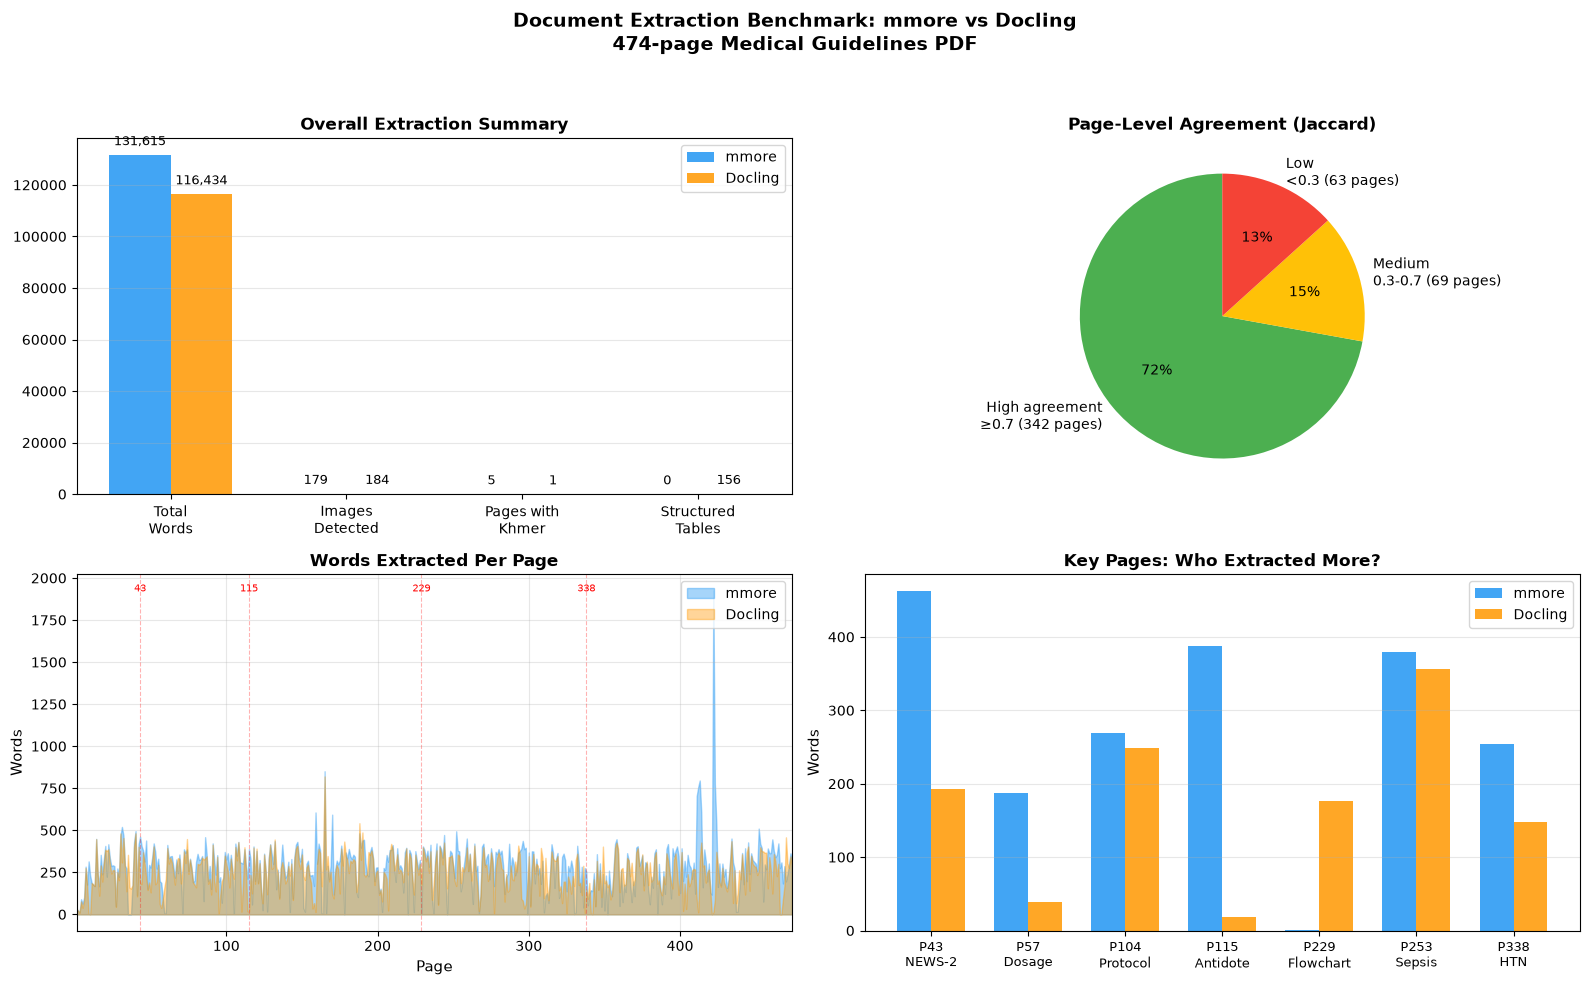

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# ---- data from your notebook results ----
mmore_words_per_page = [word_count(mmore_pages.get(p, '')) for p in range(1, 475)]
docling_words_per_page = [word_count(docling_pages.get(p, '')) for p in range(1, 475)]

sims = []
for p in range(1, 475):
    m = mmore_pages.get(p, '')
    d = docling_pages.get(p, '')
    sims.append(jaccard(m, d))

# ---- figure ----
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Document Extraction Benchmark: mmore vs Docling\n474-page Medical Guidelines PDF',
             fontsize=14, fontweight='bold', y=0.98)

# --- 1. Summary bar chart ---
ax = axes[0, 0]
metrics = ['Total\nWords', 'Images\nDetected', 'Pages with\nKhmer', 'Structured\nTables']
mmore_vals = [131615, 179, 5, 0]
docling_vals = [116434, 184, 1, 156]

x = np.arange(len(metrics))
w = 0.35
bars1 = ax.bar(x - w/2, mmore_vals, w, label='mmore', color='#2196F3', alpha=0.85)
bars2 = ax.bar(x + w/2, docling_vals, w, label='Docling', color='#FF9800', alpha=0.85)

for bar in bars1:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + max(mmore_vals)*0.02,
            f'{int(h):,}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + max(mmore_vals)*0.02,
            f'{int(h):,}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=10)
ax.set_title('Overall Extraction Summary', fontweight='bold')
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.3)

# --- 2. Agreement distribution ---
ax = axes[0, 1]
high = sum(1 for s in sims if s >= 0.7)
mid = sum(1 for s in sims if 0.3 <= s < 0.7)
low = sum(1 for s in sims if s < 0.3)

colors_pie = ['#4CAF50', '#FFC107', '#F44336']
wedges, texts, autotexts = ax.pie(
    [high, mid, low],
    labels=[f'High agreement\n≥0.7 ({high} pages)',
            f'Medium\n0.3-0.7 ({mid} pages)',
            f'Low\n<0.3 ({low} pages)'],
    colors=colors_pie, autopct='%1.0f%%',
    startangle=90, textprops={'fontsize': 10})
ax.set_title('Page-Level Agreement (Jaccard)', fontweight='bold')

# --- 3. Word count per page ---
ax = axes[1, 0]
pages = list(range(1, 475))
ax.fill_between(pages, mmore_words_per_page, alpha=0.4, color='#2196F3', label='mmore')
ax.fill_between(pages, docling_words_per_page, alpha=0.4, color='#FF9800', label='Docling')
ax.set_xlabel('Page', fontsize=11)
ax.set_ylabel('Words', fontsize=11)
ax.set_title('Words Extracted Per Page', fontweight='bold')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
ax.set_xlim(1, 474)

for p in [43, 115, 229, 338]:
    ax.axvline(x=p, color='red', alpha=0.3, linewidth=0.8, linestyle='--')
    ax.text(p, ax.get_ylim()[1]*0.95, str(p), ha='center', fontsize=7, color='red')

# --- 4. Key pages comparison ---
ax = axes[1, 1]
key_pages = [43, 57, 104, 115, 229, 253, 338]
key_labels = ['P43\nNEWS-2', 'P57\nDosage', 'P104\nProtocol', 'P115\nAntidote',
              'P229\nFlowchart', 'P253\nSepsis', 'P338\nHTN']
m_key = [word_count(mmore_pages.get(p, '')) for p in key_pages]
d_key = [word_count(docling_pages.get(p, '')) for p in key_pages]

x = np.arange(len(key_pages))
bars1 = ax.bar(x - w/2, m_key, w, label='mmore', color='#2196F3', alpha=0.85)
bars2 = ax.bar(x + w/2, d_key, w, label='Docling', color='#FF9800', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(key_labels, fontsize=9)
ax.set_ylabel('Words', fontsize=11)
ax.set_title('Key Pages: Who Extracted More?', fontweight='bold')
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('benchmark_summary.png', dpi=200, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()